# Test de Heterocedasticidad

## Si una serie es heterocedastica es **ESTRICTAMENTE ESTACIONARIA**

Tenemos dos series temporales, que se muestran a continuación:

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch


In [14]:
serie1 = pd.read_csv("serie1.csv", header=0,parse_dates=['date'], index_col='date')
serie2 = pd.read_csv("serie2.csv", header=0,parse_dates=['date'], index_col='date')

<Axes: xlabel='date'>

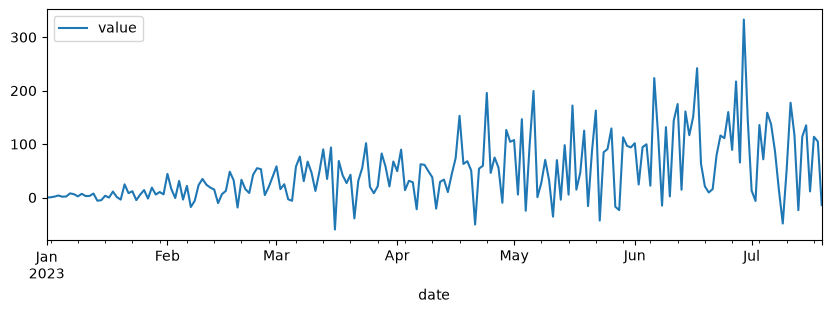

In [15]:
serie1.plot(figsize=(10,3))

<Axes: xlabel='date'>

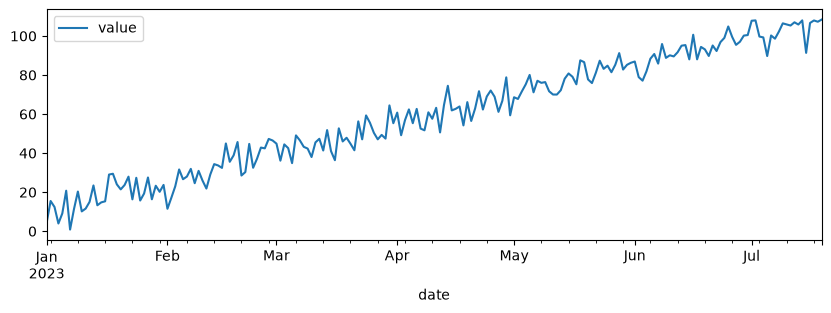

In [16]:
serie2.plot(figsize=(10,3))

Primero comprobamos los test de ADF y KPSS para comprobar si son estacionarias en tendencia.

In [17]:
serie1 = serie1.squeeze()
p_value_adf_hom = adfuller(serie1, autolag='AIC')[1]
p_value_kpss_hom = kpss(serie1)[1]
print("adf p-value para la serie 1", p_value_adf_hom)
print("kpss p-value para la serie 1", p_value_kpss_hom)

adf p-value para la serie 1 0.5467630360593178
kpss p-value para la serie 1 0.01


C:\Users\maren\AppData\Local\Temp\ipykernel_26916\2057420366.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value_adf_hom = adfuller(serie1, autolag='AIC')[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_26916\2057420366.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  p_value_kpss_hom = kpss(serie1)[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_26916\2057420366.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after Ju

Ambos test concluyen que la serie no es estacionaria, por lo tanto tiene tendencia.

In [18]:
serie2 = serie2.squeeze()
p_value_adf_het= adfuller(serie2, autolag='AIC')[1]
p_value_kpss_het= kpss(serie2)[1]
print("adf p-value para la serie 2 es", p_value_adf_het)
print("kpss p-value para la serie 2 es", p_value_kpss_het)

adf p-value para la serie 2 es 0.8446809184662529
kpss p-value para la serie 2 es 0.01


C:\Users\maren\AppData\Local\Temp\ipykernel_26916\2258149734.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value_adf_het= adfuller(serie2, autolag='AIC')[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_26916\2258149734.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  p_value_kpss_het= kpss(serie2)[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_26916\2258149734.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July

Ambos test concluyen que la serie no es estacionaria, por lo tanto tiene tendencia.

#### Eliminación de la tendencia

In [19]:
serie1_diff = serie1.diff().dropna(axis=0)
serie2_diff = serie2.diff().dropna(axis=0)

Volvemos a comprobar la estacionariedad

In [20]:
p_value_adf_hom = adfuller(serie1_diff)[1]
p_value_kpss_hom = kpss(serie1_diff)[1]
print("adf p-value para la serie 1 diferenciada es", p_value_adf_hom)
print("kpss p-value para la serie 1 diferenciada es", p_value_kpss_hom)

adf p-value para la serie 1 diferenciada es 1.4444515348087947e-08
kpss p-value para la serie 1 diferenciada es 0.1


C:\Users\maren\AppData\Local\Temp\ipykernel_26916\1847072292.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value_adf_hom = adfuller(serie1_diff)[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_26916\1847072292.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  p_value_kpss_hom = kpss(serie1_diff)[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_26916\1847072292.py:2: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 20

In [21]:
p_value_adf_hom = adfuller(serie2_diff)[1]
p_value_kpss_hom = kpss(serie2_diff)[1]
print("adf p-value para la serie 2 diferenciada es", p_value_adf_hom)
print("kpss p-value para la serie 2 diferenciada es", p_value_kpss_hom)

adf p-value para la serie 2 diferenciada es 1.0397317908517112e-14
kpss p-value para la serie 2 diferenciada es 0.1


C:\Users\maren\AppData\Local\Temp\ipykernel_26916\3192374323.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value_adf_hom = adfuller(serie2_diff)[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_26916\3192374323.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  p_value_kpss_hom = kpss(serie2_diff)[1]
C:\Users\maren\AppData\Local\Temp\ipykernel_26916\3192374323.py:2: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 20

Ambos test, para las dos series, concluyen que las series son estacionarias.

<Axes: xlabel='date'>

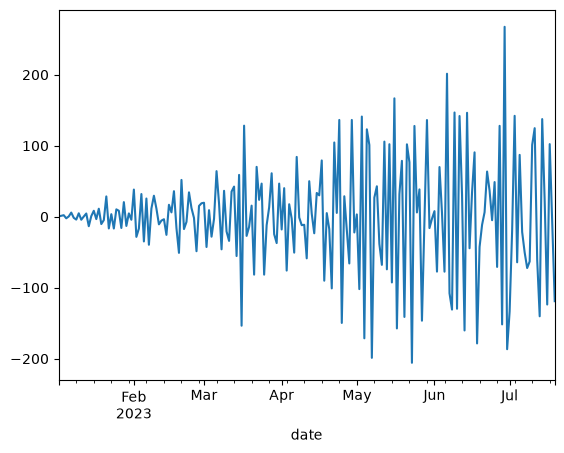

In [22]:
serie1_diff.plot()

### ¿Dirías que esta serie es estacionaria?¿Por queé?

<Axes: xlabel='date'>

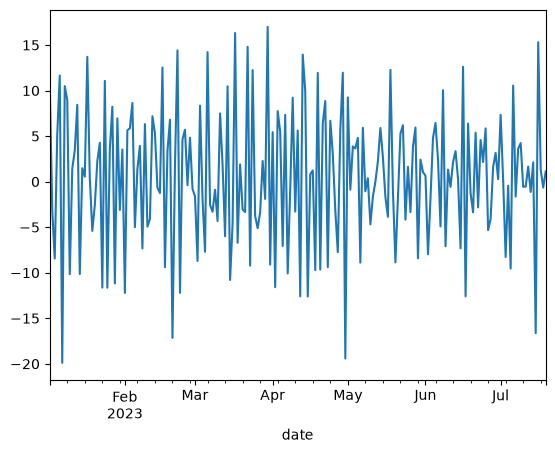

In [23]:
serie2_diff.plot()

### ¿Y esta?

Lo vamos a comprobar mediante los test de heterocedasticidad.

In [24]:
lm_test = het_arch(serie1_diff)

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test[0]:.4f}")
print(f"P-valor LM: {lm_test[1]:.4f}")
print(f"Estadístico F: {lm_test[2]:.4f}")
print(f"P-valor F: {lm_test[3]:.4f}")

Resultados del ARCH test:
Estadístico LM: 44.2922
P-valor LM: 0.0000
Estadístico F: 5.4482
P-valor F: 0.0000


c:\Users\maren\.conda\envs\datascience3\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


El p-valor < 0.05, por lo tanto, la serie presenta heterocedasticidad y por lo tanto no es estacionaria en varianza.

In [25]:
lm_test2 = het_arch(serie2_diff)

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test2[0]:.4f}")
print(f"P-valor LM: {lm_test2[1]:.4f}")
print(f"Estadístico F: {lm_test2[2]:.4f}")
print(f"P-valor F: {lm_test2[3]:.4f}")

Resultados del ARCH test:
Estadístico LM: 12.7126
P-valor LM: 0.2402
Estadístico F: 1.2836
P-valor F: 0.2427


El p-valor > 0.05, por lo que se concluye que la serie no presenta heterocedasticidad y por lo tanto es estrictamente estacionaria.